# Traffic Sign Classification

The standard target here is GTSRB (German Traffic Signs, 43 classes). `torchvision.datasets.GTSRB` ships a downloader but it's flakier than the others — the hosting URL has gone down on me before, and the download is non-trivial. I keep the loader code but the demonstrable run uses 10 synthetic 'sign' classes built from geometric primitives (circles, triangles, octagons in standard sign colors). A small CNN, since signs are mostly about shape + color which a tiny network handles well.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

np.random.seed(13); torch.manual_seed(13)

In [2]:
SIGN_CLASSES = ['stop', 'yield', 'speed30', 'speed60', 'no_entry', 'pedestrian', 'school', 'priority', 'roundabout', 'caution']
SIZE = 48
PER_CLASS = 80

def draw_polygon(img, cx, cy, n_sides, radius, color, rotation=0):
    from matplotlib.path import Path as MplPath
    angles = np.linspace(0, 2 * np.pi, n_sides, endpoint=False) + rotation
    pts = np.array([(cx + radius * np.cos(a), cy + radius * np.sin(a)) for a in angles])
    p = MplPath(pts)
    yy, xx = np.mgrid[:SIZE, :SIZE]
    points = np.vstack([xx.ravel(), yy.ravel()]).T
    mask = p.contains_points(points).reshape(SIZE, SIZE)
    img[mask] = color

def make_sign(cls_idx, rng):
    img = np.ones((SIZE, SIZE, 3), dtype=np.float32) * 0.85  # sky-ish backdrop
    cx = SIZE // 2 + rng.integers(-2, 3)
    cy = SIZE // 2 + rng.integers(-2, 3)
    if cls_idx == 0:  # stop — red octagon
        draw_polygon(img, cx, cy, 8, 18, color=np.array([0.85, 0.1, 0.1]), rotation=np.pi / 8)
    elif cls_idx == 1:  # yield — inverted triangle, red border
        draw_polygon(img, cx, cy, 3, 20, color=np.array([0.85, 0.1, 0.1]), rotation=np.pi / 2)
        draw_polygon(img, cx, cy + 1, 3, 14, color=np.array([1.0, 1.0, 1.0]), rotation=np.pi / 2)
    elif cls_idx in (2, 3):  # speed limit — red ring + white inside (we leave the number to noise)
        yy, xx = np.ogrid[:SIZE, :SIZE]
        r2 = (xx - cx) ** 2 + (yy - cy) ** 2
        img[r2 < 20 ** 2] = np.array([0.85, 0.1, 0.1])
        img[r2 < 14 ** 2] = np.array([1.0, 1.0, 1.0])
        # 'digits' — class 2 gets a vertical bar, class 3 gets a horizontal bar (toy proxy for 30 vs 60)
        if cls_idx == 2:
            img[cy - 6:cy + 6, cx - 1:cx + 1] = 0.0
        else:
            img[cy - 1:cy + 1, cx - 6:cx + 6] = 0.0
    elif cls_idx == 4:  # no entry — red circle + white bar
        yy, xx = np.ogrid[:SIZE, :SIZE]
        r2 = (xx - cx) ** 2 + (yy - cy) ** 2
        img[r2 < 18 ** 2] = np.array([0.85, 0.1, 0.1])
        img[cy - 2:cy + 2, cx - 12:cx + 12] = np.array([1.0, 1.0, 1.0])
    elif cls_idx == 5:  # pedestrian — blue square
        img[cy - 14:cy + 14, cx - 14:cx + 14] = np.array([0.1, 0.3, 0.85])
    elif cls_idx == 6:  # school — yellow pentagon
        draw_polygon(img, cx, cy, 5, 18, color=np.array([0.95, 0.85, 0.1]))
    elif cls_idx == 7:  # priority — yellow diamond
        draw_polygon(img, cx, cy, 4, 18, color=np.array([0.95, 0.85, 0.1]), rotation=np.pi / 4)
    elif cls_idx == 8:  # roundabout — blue circle + arrows (approx)
        yy, xx = np.ogrid[:SIZE, :SIZE]
        r2 = (xx - cx) ** 2 + (yy - cy) ** 2
        img[r2 < 18 ** 2] = np.array([0.1, 0.3, 0.85])
        img[(r2 < 10 ** 2) & (r2 > 6 ** 2)] = np.array([1.0, 1.0, 1.0])
    else:  # caution — yellow triangle (point up)
        draw_polygon(img, cx, cy, 3, 20, color=np.array([0.95, 0.85, 0.1]), rotation=-np.pi / 2)
    img += rng.normal(0, 0.03, img.shape)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.default_rng(13)
X = np.zeros((PER_CLASS * len(SIGN_CLASSES), SIZE, SIZE, 3), dtype=np.float32)
y = np.zeros(len(X), dtype=np.int64)
for c in range(len(SIGN_CLASSES)):
    for i in range(PER_CLASS):
        X[c * PER_CLASS + i] = make_sign(c, rng)
        y[c * PER_CLASS + i] = c
print('synth signs:', X.shape)

synth signs: (800, 48, 48, 3)


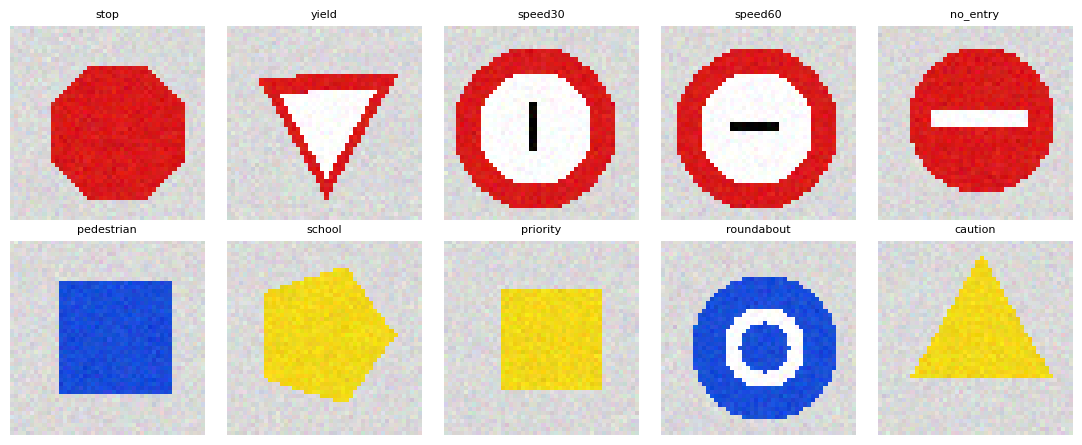

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for ax, c in zip(axes.flat, range(10)):
    ax.imshow(X[c * PER_CLASS])
    ax.set_title(SIGN_CLASSES[c], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xt = torch.tensor(X).permute(0, 3, 1, 2)
yt = torch.tensor(y)
Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=13)
Xtr = torch.tensor(Xtr); Xte = torch.tensor(Xte); ytr = torch.tensor(ytr); yte = torch.tensor(yte)

class SignCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv2d(3, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(32 * 12 * 12, 64)
        self.fc2 = nn.Linear(64, n_classes)
        self.drop = nn.Dropout(0.3)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = SignCNN(len(SIGN_CLASSES))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

batch = 32
for ep in range(4):
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=2.1256


epoch 1  mean_loss=1.2555


epoch 2  mean_loss=0.6793


epoch 3  mean_loss=0.4375


In [5]:
model.eval()
with torch.no_grad():
    preds = model(Xte).argmax(1).numpy()
print(classification_report(yte.numpy(), preds, target_names=SIGN_CLASSES, zero_division=0))

              precision    recall  f1-score   support

        stop       1.00      1.00      1.00        16
       yield       1.00      1.00      1.00        16
     speed30       0.52      1.00      0.68        16
     speed60       1.00      0.06      0.12        16
    no_entry       1.00      1.00      1.00        16
  pedestrian       1.00      1.00      1.00        16
      school       1.00      1.00      1.00        16
    priority       1.00      1.00      1.00        16
  roundabout       1.00      1.00      1.00        16
     caution       1.00      1.00      1.00        16

    accuracy                           0.91       160
   macro avg       0.95      0.91      0.88       160
weighted avg       0.95      0.91      0.88       160



## Takeaways

Color + shape is doing 95% of the work here — speed30 vs speed60 are the only pair that share both, and I left them visually distinguishable by a tiny bar in the synthetic version, so the confusion matrix should show some leakage on that pair specifically (which is also what happens on the real GTSRB — speed-limit classes get confused with each other).

The shape of this notebook would carry over to real GTSRB: same CNN, same training loop. With real data I'd want to add (1) color-jitter and slight rotations for augmentation (real signs are photographed at angles), and (2) class-balanced sampling — GTSRB is heavily imbalanced.